In [7]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [8]:
save_path = Path(
    r"C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\plan leaf disease system\prepared_data.pkl"
)

with open(save_path, "rb") as file:
    prepared_data = pickle.load(file)

train_df = prepared_data["train_df"]
val_df = prepared_data["val_df"]
test_df = prepared_data["test_df"]
class_names = prepared_data["class_names"]

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Classes:", class_names)

Training images: 5305
Validation images: 1137
Testing images: 1137
Classes: ['Tomato___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold']


In [9]:
from tensorflow.keras import layers, models

In [10]:
cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output layer: five disease categories
    layers.Dense(len(class_names), activation="softmax")
])

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 5)                   │             645 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,605 (42.61 MB)

 Trainable params: 11,169,605 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [12]:
EPOCHS = 10

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)

Epochs: 10
Batch size: 16


In [14]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

def load_cnn_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0

    return image, label

In [15]:
def create_cnn_dataset(dataframe, shuffle=False):
    image_paths = dataframe["image_path"].values
    labels = dataframe["label"].map(class_to_index).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED
        )

    dataset = dataset.map(
        load_cnn_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset

In [16]:
train_dataset = create_cnn_dataset(train_df, shuffle=True)
val_dataset = create_cnn_dataset(val_df)
test_dataset = create_cnn_dataset(test_df)

print("Training dataset:", train_dataset)
print("Validation dataset:", val_dataset)
print("Testing dataset:", test_dataset)

Training dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
Validation dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
Testing dataset: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


In [17]:
history = cnn_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Epoch 1/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 143s 422ms/step - accuracy: 0.6302 - loss: 0.9529 - val_accuracy: 0.7704 - val_loss: 0.5964
Epoch 2/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 157s 474ms/step - accuracy: 0.8164 - loss: 0.4938 - val_accuracy: 0.8575 - val_loss: 0.3558
Epoch 3/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 142s 429ms/step - accuracy: 0.8701 - loss: 0.3596 - val_accuracy: 0.9085 - val_loss: 0.2613
Epoch 4/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 151s 454ms/step - accuracy: 0.8944 - loss: 0.3016 - val_accuracy: 0.8795 - val_loss: 0.3402
Epoch 5/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 140s 420ms/step - accuracy: 0.8999 - loss: 0.2908 - val_accuracy: 0.8795 - val_loss: 0.3431
Epoch 6/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 136s 410ms/step - accuracy: 0.9123 - loss: 0.2517 - val_accuracy: 0.9006 - val_loss: 0.2917
Epoch 7/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 137s 414ms/step - accuracy: 0.9367 - loss: 0.1718 - val_accuracy: 0.9288 - val_loss: 0.1984
Epoch 8/10
332/332 ━━━━━━━━━━━━━━━━━━━━ 136s 409ms/step - accuracy: 0.9369 -

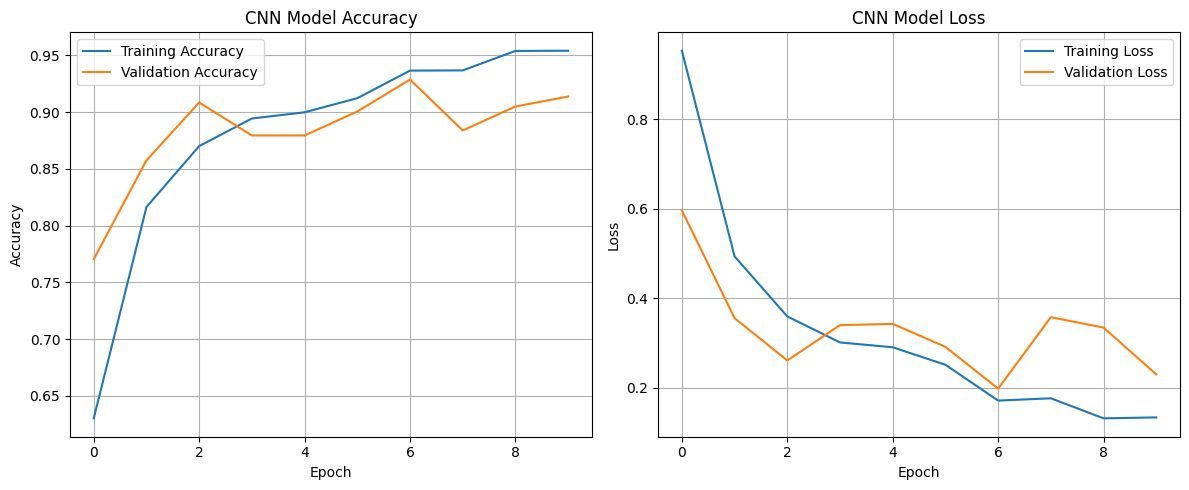

In [19]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [20]:
test_loss, test_accuracy = cnn_model.evaluate(test_dataset)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

72/72 ━━━━━━━━━━━━━━━━━━━━ 9s 117ms/step - accuracy: 0.9305 - loss: 0.2259
Test Loss: 0.2259
Test Accuracy: 93.05 %


In [21]:
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = cnn_model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_classes)

print("Predictions generated successfully!")

Predictions generated successfully!


In [22]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

                         precision    recall  f1-score   support

       Tomato___healthy       0.99      0.99      0.99       238
Tomato___Bacterial_spot       0.93      0.98      0.95       319
  Tomato___Early_blight       0.84      0.75      0.79       150
   Tomato___Late_blight       0.92      0.93      0.92       287
     Tomato___Leaf_Mold       0.95      0.91      0.93       143

               accuracy                           0.93      1137
              macro avg       0.92      0.91      0.92      1137
           weighted avg       0.93      0.93      0.93      1137



<Figure size 900x700 with 0 Axes>

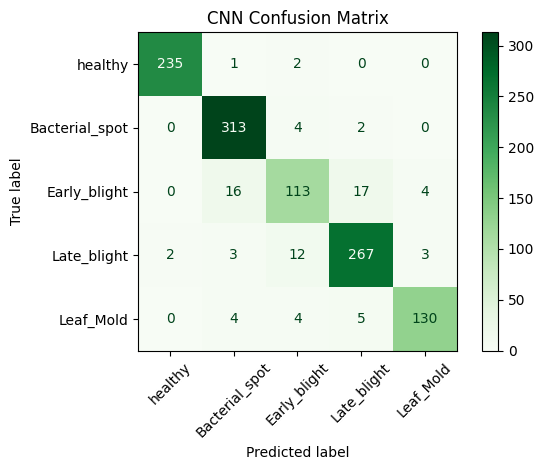

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        name.replace("Tomato___", "")
        for name in class_names
    ]
)

disp.plot(cmap="Greens", values_format="d")
plt.title("CNN Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
import os

os.makedirs("models", exist_ok=True)

cnn_model.save("models/custom_cnn.keras")

print("CNN model saved successfully!")

CNN model saved successfully!


In [25]:
import shutil
from pathlib import Path

project = Path(
    r"C:\Users\ABHAY YADAV\OneDrive\Desktop\ghub\plan leaf disease system"
)

models_folder = project / "models"
models_folder.mkdir(parents=True, exist_ok=True)

# Copy Custom CNN
cnn_source = Path(r"C:\Users\ABHAY YADAV\models\custom_cnn.keras")

if cnn_source.exists():
    shutil.copy2(cnn_source, models_folder / "custom_cnn.keras")
    print("Custom CNN copied successfully!")
else:
    print("Custom CNN not found at:", cnn_source)

# Check both models
for model in models_folder.glob("*.keras"):
    print(model.name, ":", round(model.stat().st_size / (1024 * 1024), 2), "MB")

Custom CNN copied successfully!
custom_cnn.keras : 127.87 MB
mobilenetv2.keras : 11.06 MB
